# Airline Review Analysis - Notebook 8: Business Insights

Now I use the topic sentiments to answer questions an airline would ask:
1. Which problems are the most serious?
2. Is it the delay itself, or how the airline handles it?
3. How do airlines compare?
4. Are things getting better or worse over time?
5. Do different passengers complain about different things?

A **complaint** in this notebook means a review with a *negative* sentiment about a topic (from Notebook 6). All the analysis uses simple counts and percentages.

Input: `data/reviews_preprocessed.csv`, `data/aspect_reviews.csv`
Output: three small tables in `data/` for the dashboard

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 100)

df = pd.read_csv("data/reviews_preprocessed.csv", parse_dates=["review_date"])
aspect_reviews = pd.read_csv("data/aspect_reviews.csv")

topics = sorted(aspect_reviews["topic"].unique())
print(len(df), "reviews,", len(topics), "topics")

64331 reviews, 13 topics


For every review I make a table with one column per topic: 1 if the review has a negative sentiment about that topic, otherwise 0.

In [2]:
negative = aspect_reviews[aspect_reviews["label"] == "negative"].copy()
negative["complaint"] = 1

complaints = negative.pivot_table(index="review_id", columns="topic", values="complaint", fill_value=0)
complaints = complaints.reindex(index=df.index, columns=topics, fill_value=0)     # reviews without complaints get 0

data = df[["airline", "year", "recommended_bin", "seat_type", "type_of_traveller"]].join(complaints)
data.head()

,airline,year,recommended_bin,seat_type,type_of_traveller,baggage,boarding_checkin,cabin_crew,cancellation,communication,delay,entertainment,food,ground_staff,refund_compensation,seat,value_fees,wifi
0,Spicejet,2025,0,Economy Class,Business,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Spicejet,2025,0,Economy Class,Family Leisure,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Spicejet,2025,0,Economy Class,Business,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,Spicejet,2025,0,Economy Class,Business,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,Spicejet,2025,0,Economy Class,Solo Leisure,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [3]:
number_of_complaints = data[topics].sum(axis=1)
print("reviews with at least one complaint:", round((number_of_complaints > 0).mean() * 100, 1), "%")
print("average number of complaints per review:", round(number_of_complaints.mean(), 2))

reviews with at least one complaint: 63.1 %
average number of complaints per review: 1.53


One thing to keep in mind: the topic sentiments come from a model that was trained on 80% of the reviews, so for those reviews they can be slightly optimistic. In Notebook 7 the scores were checked on unseen reviews and held up well.

## 2. Which problems are the most serious?

Two things make a problem important: how **often** it appears, and how **much it hurts**. To measure the damage I compare the percentage of passengers who still recommend the airline when the complaint is present with when it is not present.

In [4]:
overall_rate = data["recommended_bin"].mean() * 100
print("overall recommendation rate:", round(overall_rate, 1), "%")

rows = []
for topic in topics:
    has_complaint = data[topic] == 1
    rate_with = data.loc[has_complaint, "recommended_bin"].mean() * 100
    rate_without = data.loc[~has_complaint, "recommended_bin"].mean() * 100
    rows.append({"topic": topic,
                 "reviews with complaint": has_complaint.sum(),
                 "% of all reviews": has_complaint.mean() * 100,
                 "recommend rate with complaint": rate_with,
                 "recommend rate without": rate_without,
                 "drop (points)": rate_without - rate_with})

problems = pd.DataFrame(rows).set_index("topic").round(1)
problems = problems.sort_values("drop (points)", ascending=False)
problems

overall recommendation rate: 38.3 %


,reviews with complaint,% of all reviews,recommend rate with complaint,recommend rate without,drop (points)
topic,,,,,
refund_compensation,7915,12.3,2.7,43.3,40.6
ground_staff,11705,18.2,5.4,45.6,40.1
cancellation,6114,9.5,3.6,41.9,38.3
delay,11049,17.2,7.6,44.6,37.0
value_fees,11528,17.9,8.3,44.8,36.5
communication,8340,13.0,6.7,43.0,36.2
boarding_checkin,9568,14.9,7.6,43.6,36.0
baggage,9463,14.7,9.1,43.3,34.2
cabin_crew,4968,7.7,7.2,40.9,33.6


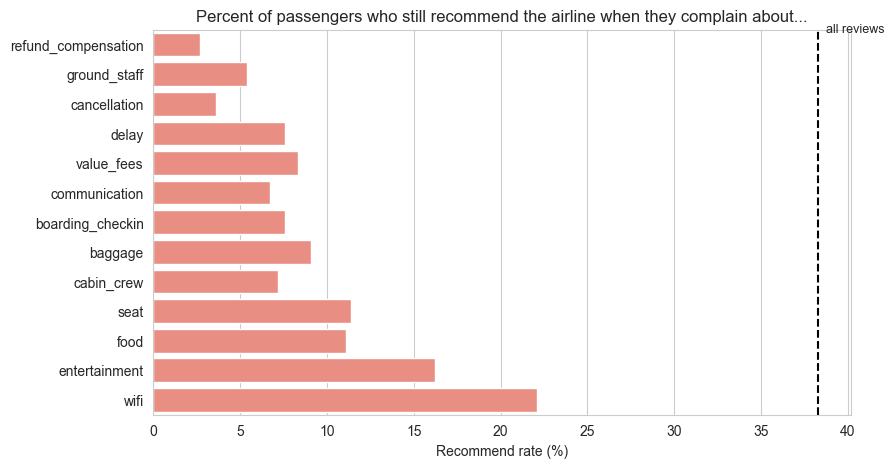

In [5]:
plt.figure(figsize=(9, 5))
sns.barplot(x=problems["recommend rate with complaint"], y=problems.index, color="salmon")
plt.axvline(overall_rate, color="black", linestyle="--")
plt.text(overall_rate + 0.5, -0.4, "all reviews", fontsize=9)
plt.title("Percent of passengers who still recommend the airline when they complain about...")
plt.xlabel("Recommend rate (%)")
plt.ylabel("")
plt.show()

**Observations**

Whenever a passenger complains about one of these topics, the chance of recommending the airline falls a lot, from 38% overall to between 3% and 22%. The most damaging complaints are **refund / compensation (only 2.7% still recommend), cancellation (3.6%) and ground staff (5.4%)**. Complaints about entertainment and WiFi hurt much less (16% and 22% still recommend), probably because these are extras that are not essential for the journey.

### Frequency and damage together

I combine both ideas in a **priority score**: the share of all reviews that have the complaint, multiplied by the drop in recommendation rate. A problem that is both common and damaging gets a high score.

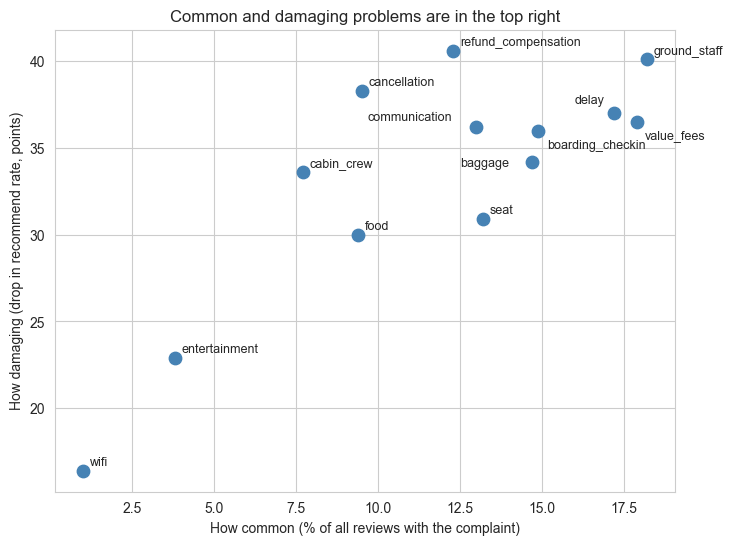

,% of all reviews,drop (points),priority score
topic,,,
ground_staff,18.2,40.1,7.30
value_fees,17.9,36.5,6.53
delay,17.2,37.0,6.36
boarding_checkin,14.9,36.0,5.36
baggage,14.7,34.2,5.03
refund_compensation,12.3,40.6,4.99
communication,13.0,36.2,4.71
seat,13.2,30.9,4.08
cancellation,9.5,38.3,3.64


In [6]:
problems["priority score"] = (problems["% of all reviews"] / 100 * problems["drop (points)"]).round(2)
priority = problems.sort_values("priority score", ascending=False)

plt.figure(figsize=(8, 6))
plt.scatter(problems["% of all reviews"], problems["drop (points)"], s=80, color="steelblue")
offsets = {"communication": (-78, 5), "boarding_checkin": (6, -13), "baggage": (-52, -3), "delay": (-28, 7), "value_fees": (6, -12)}
for topic, row in problems.iterrows():
    plt.annotate(topic, (row["% of all reviews"], row["drop (points)"]), xytext=offsets.get(topic, (5, 4)), textcoords="offset points", fontsize=9)
plt.xlabel("How common (% of all reviews with the complaint)")
plt.ylabel("How damaging (drop in recommend rate, points)")
plt.title("Common and damaging problems are in the top right")
plt.show()

priority[["% of all reviews", "drop (points)", "priority score"]]

**Observations**

The topics that are both common and damaging are **ground staff (18% of reviews, priority score 7.3), value / fees (6.5) and delay (6.4)**, followed by boarding and check-in, baggage and refund. Refund and cancellation are very damaging but less common, and WiFi and entertainment are neither common nor damaging.

Note that ground staff and value / fees were the two topics with weaker validation in Notebook 7, so their high position should be read with some care.

### A second opinion with Logistic Regression

The comparison above has a weakness: complaints often come together (a review that complains about a cancellation probably also complains about a refund). A Logistic Regression looks at all complaints at the same time, so each coefficient shows the effect of one complaint **while the others are taken into account**. A more negative coefficient means a bigger drop in the chance of recommending.

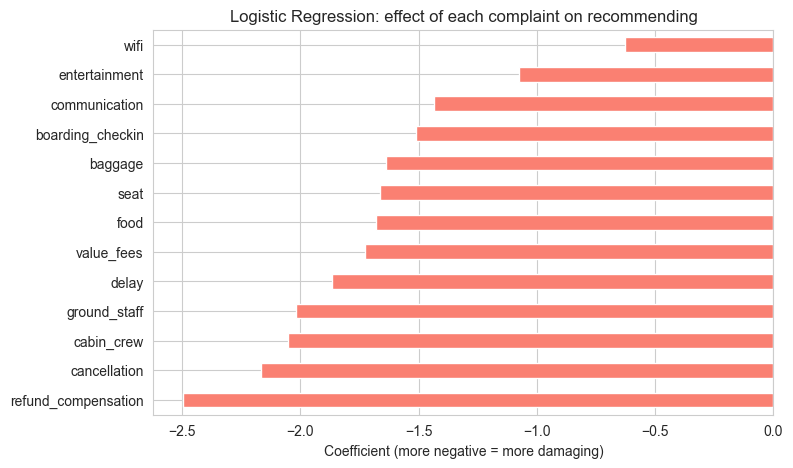

,damage rank (comparison),damage rank (Logistic Regression)
refund_compensation,1,1
ground_staff,2,4
cancellation,3,2
delay,4,5
value_fees,5,6
communication,6,11
boarding_checkin,7,10
baggage,8,9
cabin_crew,9,3
seat,10,8


In [7]:
lr = LogisticRegression(max_iter=1000)
lr.fit(data[topics], data["recommended_bin"])

coefficients = pd.Series(lr.coef_[0], index=topics).sort_values()

plt.figure(figsize=(8, 5))
coefficients.plot(kind="barh", color="salmon")
plt.title("Logistic Regression: effect of each complaint on recommending")
plt.xlabel("Coefficient (more negative = more damaging)")
plt.show()

ranking = pd.DataFrame({"damage rank (comparison)": problems["drop (points)"].rank(ascending=False).astype(int),
                        "damage rank (Logistic Regression)": coefficients.rank().astype(int)}).sort_values("damage rank (comparison)")
ranking

**Observations**

Both methods put refund / compensation first, with cancellation, ground staff and delay in the top five, and entertainment and WiFi at the bottom. There are two interesting differences:
- **Cabin crew** moves from 9th to 3rd. A complaint about the crew is not common, but it hurts even when nothing else went wrong.
- **Communication** moves from 6th to 11th. This suggests that much of its damage in the simple comparison is shared with delays and cancellations that happen together with it.

## 3. Is it the delay, or the lack of communication?

I look at passengers who complain about a delay or a cancellation, and split them into those who **also** complain about communication (no information, no updates) and those who do not.

In [8]:
disrupted = data[(data["delay"] == 1) | (data["cancellation"] == 1)].copy()
disrupted["group"] = np.where(disrupted["communication"] == 1,
                              "delay/cancellation + communication complaint",
                              "delay/cancellation only")

comparison = disrupted.groupby("group")["recommended_bin"].agg(["count", "mean"])
comparison["mean"] = (comparison["mean"] * 100).round(1)
comparison.columns = ["reviews", "recommend rate (%)"]
comparison

,reviews,recommend rate (%)
group,,
delay/cancellation + communication complaint,4261,3.4
delay/cancellation only,10748,8.2


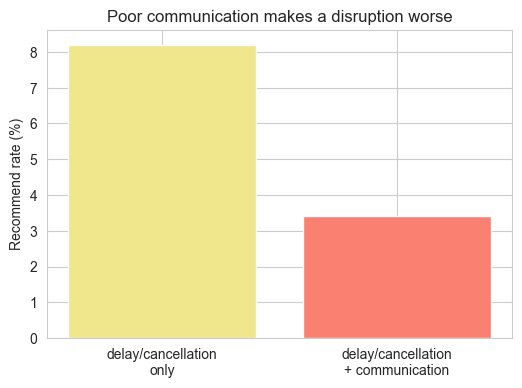

In [9]:
plt.figure(figsize=(6, 4))
order = ["delay/cancellation only", "delay/cancellation + communication complaint"]
plt.bar(["delay/cancellation\nonly", "delay/cancellation\n+ communication"], comparison.loc[order, "recommend rate (%)"], color=["khaki", "salmon"])
plt.ylabel("Recommend rate (%)")
plt.title("Poor communication makes a disruption worse")
plt.show()

**Observations**

Among passengers who complain about a delay or cancellation, only 3.4% still recommend the airline if they also complain about communication, compared with 8.2% if they do not. So poor communication cuts the recommendation rate by more than half again. This points to a clear action: how the airline informs passengers during a disruption matters on top of the disruption itself.

As always this is an association and not proof of cause: very angry passengers may complain about everything.

## 4. Comparing airlines

To keep the numbers reliable I only use airlines with at least 300 reviews. For each airline and topic I calculate the **complaint rate**: the percentage of the airline's reviews that complain about that topic.

52 airlines with at least 300 reviews


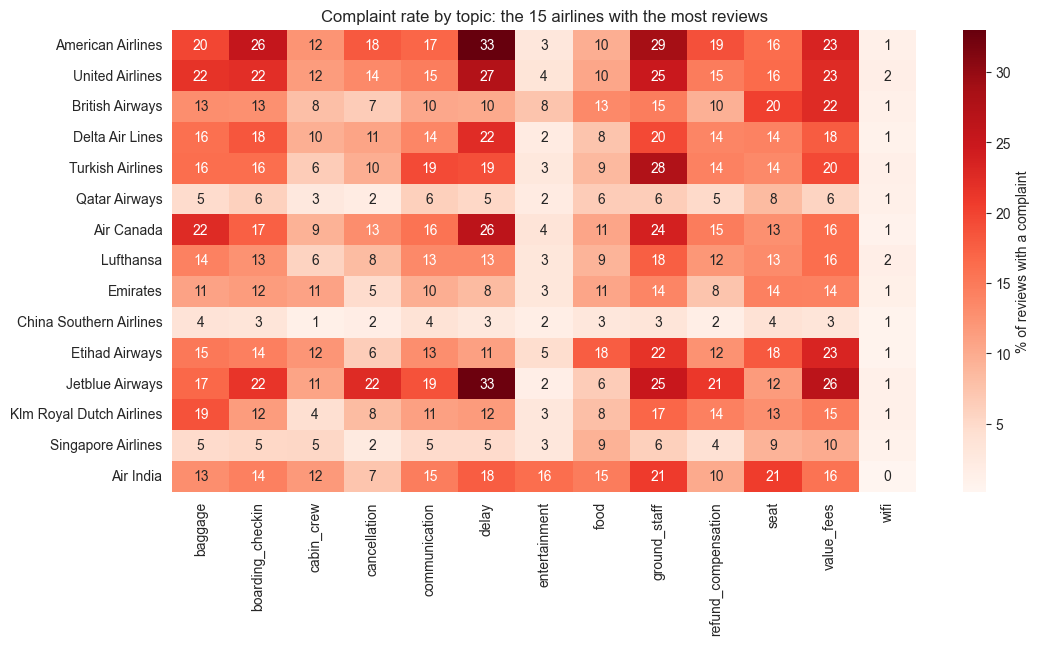

In [10]:
airline_sizes = data["airline"].value_counts()
big_airlines = airline_sizes[airline_sizes >= 300].index
print(len(big_airlines), "airlines with at least 300 reviews")

airline_rates = (data[data["airline"].isin(big_airlines)].groupby("airline")[topics].mean() * 100).round(1)
airline_rates["reviews"] = airline_sizes[airline_rates.index]
airline_rates["recommend rate (%)"] = (data[data["airline"].isin(big_airlines)].groupby("airline")["recommended_bin"].mean() * 100).round(1)

top15 = airline_rates.sort_values("reviews", ascending=False).head(15)

plt.figure(figsize=(12, 6))
sns.heatmap(top15[topics], annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of reviews with a complaint"})
plt.title("Complaint rate by topic: the 15 airlines with the most reviews")
plt.ylabel("")
plt.show()

**Observations**

The complaint pattern differs by airline. The big US airlines and Air Canada (American, United, Delta, JetBlue) have **delay** and **ground staff** as their most common complaints. Qatar, Emirates and Singapore Airlines, which are recommended much more often, get their complaints mainly about **seat, food and price**, which are comfort and cost issues and not operational ones. British Airways and Etihad are mostly criticised for value / fees.

China Southern has a very high recommendation rate (89%), which may partly reflect who writes reviews for that airline.

In [11]:
# the three topics each airline gets the most complaints about
weak_points = {}
for airline, row in top15[topics].iterrows():
    weak_points[airline] = ", ".join(row.sort_values(ascending=False).head(3).index)

summary = top15[["reviews", "recommend rate (%)"]].copy()
summary["main complaint topics"] = pd.Series(weak_points)
summary

,reviews,recommend rate (%),main complaint topics
airline,,,
American Airlines,5872,12.5,"delay, ground_staff, boarding_checkin"
United Airlines,4486,18.1,"delay, ground_staff, value_fees"
British Airways,3445,37.4,"value_fees, seat, ground_staff"
Delta Air Lines,2837,28.9,"delay, ground_staff, boarding_checkin"
Turkish Airlines,2426,32.5,"ground_staff, value_fees, communication"
Qatar Airways,2283,73.4,"seat, food, ground_staff"
Air Canada,2115,26.1,"delay, ground_staff, baggage"
Lufthansa,2115,42.7,"ground_staff, value_fees, baggage"
Emirates,1965,44.9,"seat, value_fees, ground_staff"


A small function to compare two airlines directly (this will also be used in the dashboard):

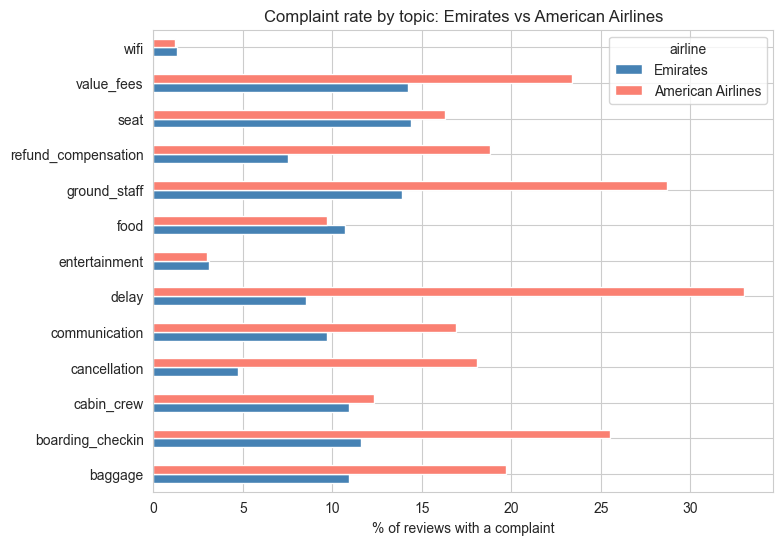

In [12]:
def compare_airlines(first, second):
    both = airline_rates.loc[[first, second], topics].T
    both.plot(kind="barh", figsize=(8, 6), color=["steelblue", "salmon"])
    plt.title("Complaint rate by topic: " + first + " vs " + second)
    plt.xlabel("% of reviews with a complaint")
    plt.show()

compare_airlines("Emirates", "American Airlines")

## 5. Changes over time

For the six most serious problems: what percentage of reviews in each year contains this complaint? (2020 and 2021 are the COVID years, and 2025 only goes up to August.)

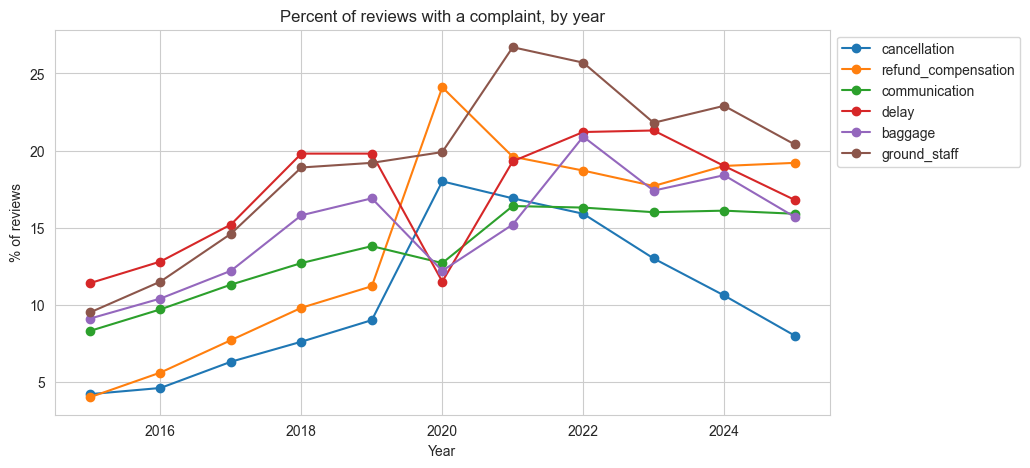

,cancellation,refund_compensation,communication,delay,baggage,ground_staff
year,,,,,,
2015,4.2,4.0,8.3,11.4,9.1,9.5
2016,4.6,5.6,9.7,12.8,10.4,11.5
2017,6.3,7.7,11.3,15.2,12.2,14.6
2018,7.6,9.8,12.7,19.8,15.8,18.9
2019,9.0,11.2,13.8,19.8,16.9,19.2
2020,18.0,24.1,12.7,11.5,12.2,19.9
2021,16.9,19.6,16.4,19.3,15.2,26.7
2022,15.9,18.7,16.3,21.2,20.9,25.7
2023,13.0,17.7,16.0,21.3,17.4,21.8


In [13]:
trend = (data.groupby("year")[topics].mean() * 100).round(1)

main_problems = ["cancellation", "refund_compensation", "communication", "delay", "baggage", "ground_staff"]
trend[main_problems].plot(figsize=(10, 5), marker="o")
plt.title("Percent of reviews with a complaint, by year")
plt.ylabel("% of reviews")
plt.xlabel("Year")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

trend[main_problems]

**Observations**

Complaints have grown over the years. From 2015 to 2022 the share of reviews complaining about delay rose from 11% to 21%, baggage from 9% to 21%, ground staff from 10% to about 26%, and communication from 8% to 16%.

**Cancellation and refund complaints jumped in 2020 (18% and 24%)** during COVID. Cancellation complaints have fallen to 8% in 2025, but **refund complaints are still high (19%)**, so refunds remain a problem long after the cancellations. Part of the change over the years may also be due to how people write reviews.

## 6. Do different passengers complain about different things?

Complaint rate by seat class and by traveller type. Groups with fewer than 100 reviews are left out.

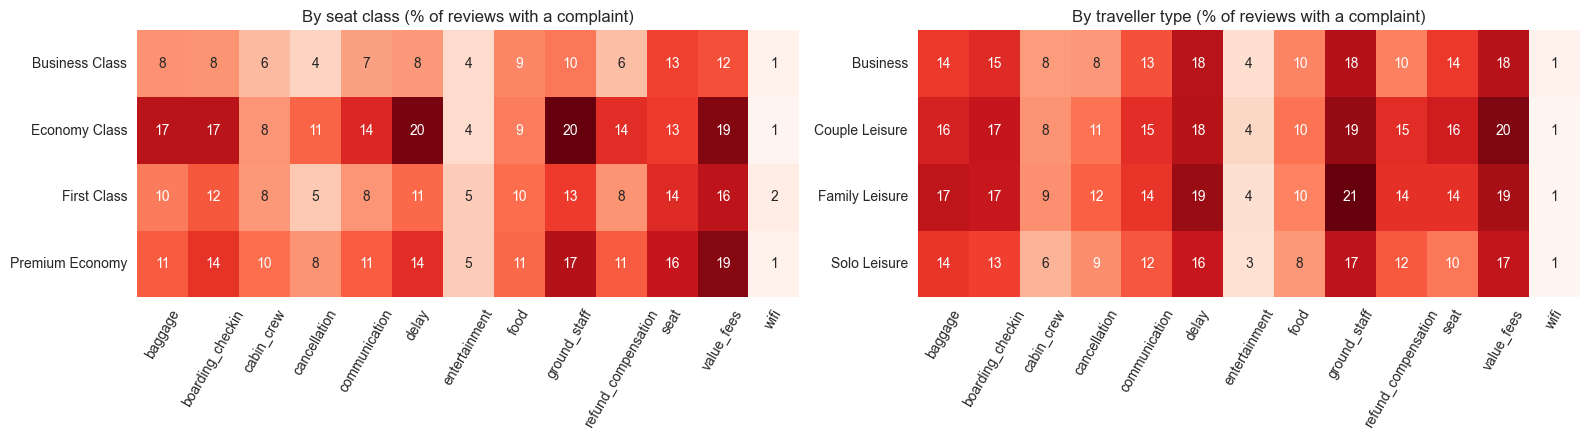

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

for ax, column, title in [(axes[0], "seat_type", "By seat class"), (axes[1], "type_of_traveller", "By traveller type")]:
    sizes = data[column].value_counts()
    groups = sizes[sizes >= 100].index
    rates = data[data[column].isin(groups)].groupby(column)[topics].mean() * 100
    sns.heatmap(rates, annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=ax)
    ax.set_title(title + " (% of reviews with a complaint)")
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

**Observations**

Economy passengers complain about operational problems about twice as often as business class passengers: delay (20% against 8%), baggage (17% against 8%), boarding (17% against 8%), ground staff (20% against 10%), cancellation (11% against 4%) and refunds (14% against 6%).

Complaints about the seat, food and entertainment are about the same in every class, and business class passengers complain about their seat as often as economy passengers (13% each). Between traveller types the differences are small: family leisure travellers complain a little more (for example 21% about ground staff) and solo leisure travellers the least.

## 7. Saving tables for the dashboard

In [15]:
airline_rates.to_csv("data/airline_topic_rates.csv")
trend.to_csv("data/topic_trend_by_year.csv")
problems.to_csv("data/topic_priority.csv")
print("saved 3 tables in data/")

saved 3 tables in data/


## Summary

- 63% of reviews contain at least one complaint about a topic, and a review has 1.5 complaints on average.
- Every complaint cuts the recommendation rate strongly. The most damaging are refund / compensation, cancellation, ground staff and delay. The most common and damaging together are ground staff, value / fees and delay.
- Poor communication during a delay or cancellation cuts the recommendation rate by more than half again (3.4% against 8.2%).
- Airlines have different weak points: delay and ground staff for the large US airlines, seat, food and price for the highly rated Gulf and Asian airlines.
- Complaints about delays, baggage, ground staff and communication roughly doubled between 2015 and 2022. Refund complaints stay high after COVID.
- Economy passengers complain about operational problems about twice as often as business class passengers.

Limits: these are reviews written by people who chose to write, the results show association and not cause, and ground staff and value / fees are the less reliable topics from Notebook 7.

The tables saved in `data/` (`airline_topic_rates.csv`, `topic_trend_by_year.csv`, `topic_priority.csv`) will be used in the next notebook and in the dashboard.

Next notebook: automatic recommendations for an airline, using the complaint topics and the most common complaint phrases.